# Visualisation des carreaux Filosofi 2021 (200 m)

Population par carreau de 200 m : région Auvergne-Rhône-Alpes.

In [1]:
import os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
RACINE = next(d for d in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
              if (d / "population" / "requirements.txt").is_file())

NOM = "Auvergne-Rhône-Alpes"
FICHIER = str(RACINE / "population/reference/filosofi_2021_aura/carreaux_200m_aura.csv")
FICHIERS = {NOM: FICHIER}
print("Fichier trouvé :", os.path.exists(FICHIER))

Fichier trouvé : True


## 1. Aperçu brut

In [2]:
duckdb.sql(f"SELECT * FROM read_csv('{next(iter(FICHIERS.values()))}', types={{'lcog_geo': 'VARCHAR'}}) LIMIT 5").df()

,idcar_200m,lon,lat,lcog_geo,i_est_200,ind,men,men_pauv,men_coll,ind_snv,ind_0_3,ind_4_5,ind_6_10,ind_11_17,ind_18_24,ind_25_39,ind_40_54,ind_55_64,ind_65_79,ind_80p
0,CRS3035RES200mN2344800E3959000,5.485974,44.115988,"84120,26135",1,7.0,3.2,0.5,0.0,165836.5,0.0,0.1,0.4,0.7,0.3,0.4,1.2,0.8,2.5,0.6
1,CRS3035RES200mN2345000E3958600,5.480852,44.117571,"84120,26135",1,2.0,0.9,0.2,0.0,47381.9,0.0,0.0,0.1,0.2,0.1,0.1,0.4,0.2,0.7,0.2
2,CRS3035RES200mN2345000E3960400,5.503259,44.118548,26135,1,1.0,0.5,0.2,0.1,24802.0,0.1,0.0,0.1,0.0,0.1,0.2,0.2,0.2,0.1,0.0
3,CRS3035RES200mN2345200E3958000,5.473241,44.119045,"26135,84120",1,1.0,0.5,0.1,0.0,23690.9,0.0,0.0,0.1,0.1,0.0,0.1,0.2,0.1,0.3,0.1
4,CRS3035RES200mN2345600E3958000,5.472956,44.122645,26135,1,2.0,0.9,0.2,0.0,47381.9,0.0,0.0,0.1,0.2,0.1,0.1,0.4,0.2,0.7,0.2


## 2. Chargement avec coordonnées GPS

Le fichier contient déjà `lon` et `lat`, le centre du carreau en WGS84 (voir `DATA_DICTIONARY.md`) : on les lit directement au lieu de les recalculer depuis `idcar_200m`.

In [3]:
def charger(nom):
    df = duckdb.sql(f"""
        SELECT
            lon, lat, lcog_geo,
            ind, men, men_pauv, men_coll, ind_snv,
            ind_0_3, ind_4_5, ind_6_10, ind_11_17, ind_18_24,
            ind_25_39, ind_40_54, ind_55_64, ind_65_79, ind_80p
        FROM read_csv('{FICHIERS[nom]}', types={{'lcog_geo': 'VARCHAR'}})
    """).df()
    df["territoire"] = nom
    df["dep"] = df["lcog_geo"].where(~df["lcog_geo"].str.startswith("97"), None).str[:2]
    df.loc[df["lcog_geo"].str.startswith("97"), "dep"] = df["lcog_geo"].str[:3]
    df["niveau_vie"] = df["ind_snv"] / df["ind"]
    df["part_65p"] = (df["ind_65_79"] + df["ind_80p"]) / df["ind"]
    return df

donnees = {nom: charger(nom) for nom in FICHIERS}
carreaux = pd.concat(donnees.values(), ignore_index=True)
carreaux.head()

,lon,lat,lcog_geo,ind,men,men_pauv,men_coll,ind_snv,ind_0_3,ind_4_5,...,ind_18_24,ind_25_39,ind_40_54,ind_55_64,ind_65_79,ind_80p,territoire,dep,niveau_vie,part_65p
0,5.485974,44.115988,"84120,26135",7.0,3.2,0.5,0.0,165836.5,0.0,0.1,...,0.3,0.4,1.2,0.8,2.5,0.6,Auvergne-Rhône-Alpes,84,23690.928571,0.442857
1,5.480852,44.117571,"84120,26135",2.0,0.9,0.2,0.0,47381.9,0.0,0.0,...,0.1,0.1,0.4,0.2,0.7,0.2,Auvergne-Rhône-Alpes,84,23690.950000,0.450000
2,5.503259,44.118548,26135,1.0,0.5,0.2,0.1,24802.0,0.1,0.0,...,0.1,0.2,0.2,0.2,0.1,0.0,Auvergne-Rhône-Alpes,26,24802.000000,0.100000
3,5.473241,44.119045,"26135,84120",1.0,0.5,0.1,0.0,23690.9,0.0,0.0,...,0.0,0.1,0.2,0.1,0.3,0.1,Auvergne-Rhône-Alpes,26,23690.900000,0.400000
4,5.472956,44.122645,26135,2.0,0.9,0.2,0.0,47381.9,0.0,0.0,...,0.1,0.1,0.4,0.2,0.7,0.2,Auvergne-Rhône-Alpes,26,23690.950000,0.450000


## 3. Chiffres clés

In [4]:
resume = carreaux.groupby("territoire").agg(
    carreaux=("ind", "size"),
    habitants=("ind", "sum"),
    habitants_moyens_par_carreau=("ind", "mean"),
).round(1)
resume

,carreaux,habitants,habitants_moyens_par_carreau
territoire,,,
Auvergne-Rhône-Alpes,312143,7703555.5,24.7


## 4. Répartition de la population par carreau

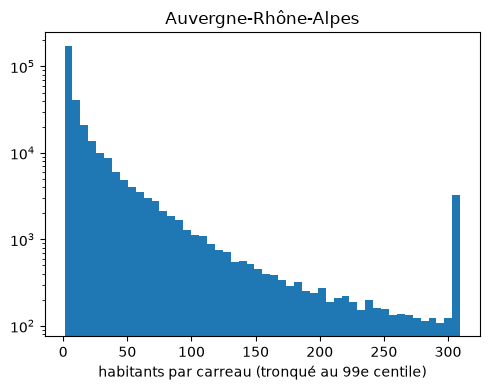

In [5]:
fig, axes = plt.subplots(1, len(donnees), figsize=(5 * len(donnees), 4), squeeze=False)
axes = axes[0]
for ax, (nom, df) in zip(axes, donnees.items()):
    ax.hist(df["ind"].clip(upper=df["ind"].quantile(0.99)), bins=50)
    ax.set_title(nom)
    ax.set_xlabel("habitants par carreau (tronqué au 99e centile)")
    ax.set_yscale("log")
plt.tight_layout()
plt.show()

## 5. Cartes de densité

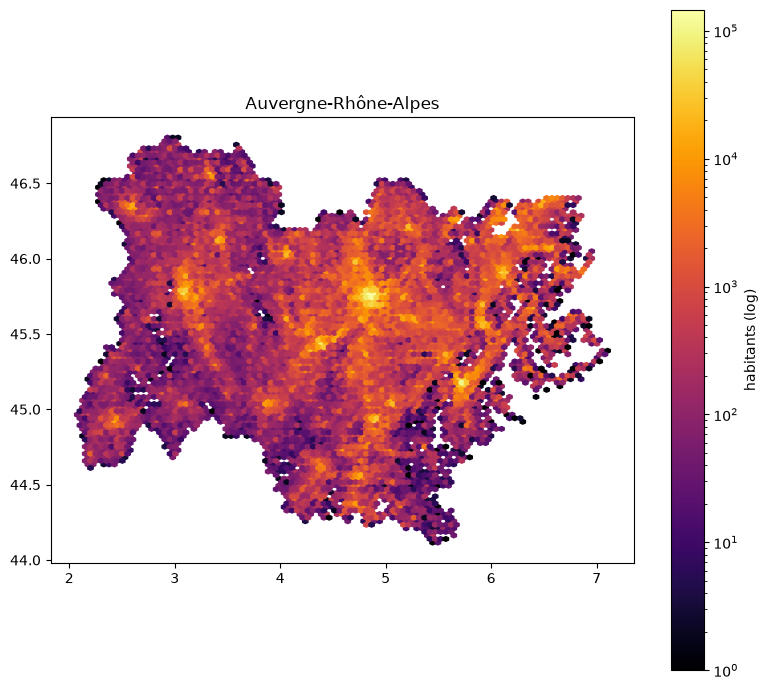

In [6]:
fig, axes = plt.subplots(1, len(donnees), figsize=(8 * len(donnees), 7), squeeze=False)
axes = axes[0]
for ax, (nom, df) in zip(axes, donnees.items()):
    hb = ax.hexbin(df["lon"], df["lat"], C=df["ind"], reduce_C_function=sum,
                   gridsize=100,
                   bins="log", cmap="inferno", mincnt=1)
    ax.set_title(nom)
    ax.set_aspect(1 / 0.7)  # correction de la déformation à ~45° de latitude
    plt.colorbar(hb, ax=ax, label="habitants (log)")
plt.tight_layout()
plt.show()

## 6. Population par département (top 15)

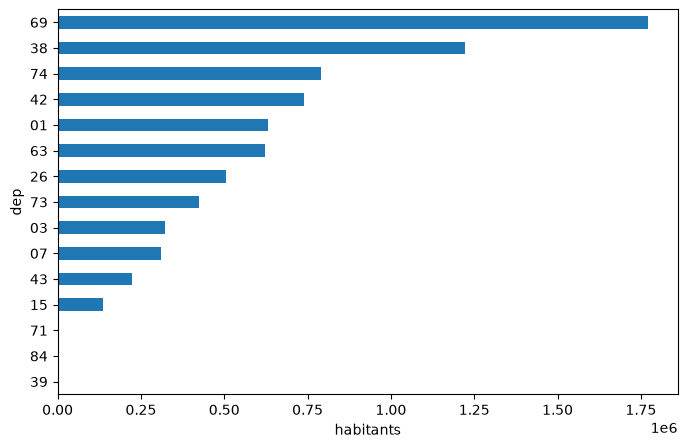

In [7]:
par_dep = carreaux.groupby("dep")["ind"].sum().sort_values(ascending=False)
par_dep.head(15).plot.barh(figsize=(8, 5)).invert_yaxis()
plt.xlabel("habitants")
plt.show()

## 7. Structure par âge

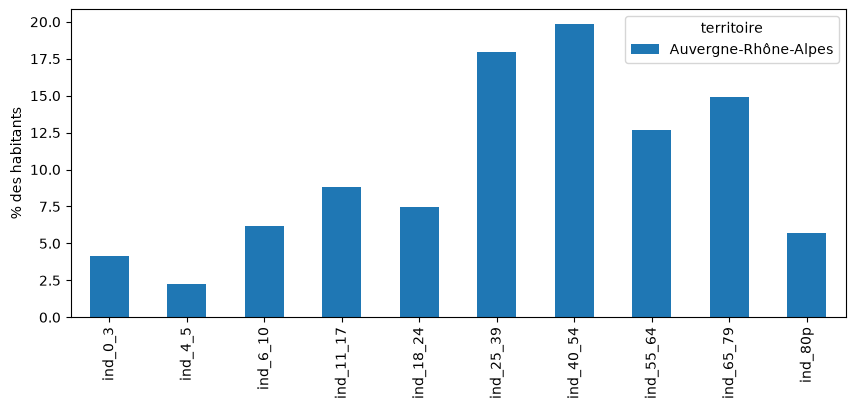

In [8]:
ages = ["ind_0_3", "ind_4_5", "ind_6_10", "ind_11_17", "ind_18_24",
        "ind_25_39", "ind_40_54", "ind_55_64", "ind_65_79", "ind_80p"]
repartition = carreaux.groupby("territoire")[ages].sum()
(repartition.div(repartition.sum(axis=1), axis=0) * 100).T.plot.bar(figsize=(10, 4))
plt.ylabel("% des habitants")
plt.show()

## 8. Niveau de vie moyen par carreau

Carreaux d'au moins 10 habitants, pour limiter le bruit.

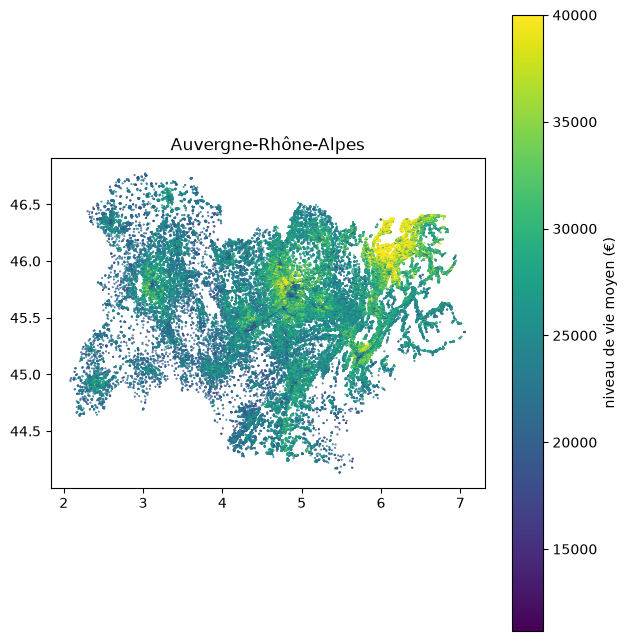

In [9]:
dense = donnees[NOM].query("ind >= 10")
plt.figure(figsize=(7, 8))
sc = plt.scatter(dense["lon"], dense["lat"], c=dense["niveau_vie"].clip(10000, 40000),
                 s=0.2, cmap="viridis")
plt.colorbar(sc, label="niveau de vie moyen (€)")
plt.gca().set_aspect(1 / 0.7)
plt.title(NOM)
plt.show()